# BloodMNIST+

datasource: [BloodMNIST+](https://www.UCI.edu/ml/datasets/BloodMNIST%2B)

In [ ]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Image processing
from PIL import Image
from torchvision import transforms
import tensorflow as tf

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

## Loading the dataset

In [3]:
path = "../data/raw/bloodmnist_128.npz"

df_raw = np.load(path)
df_raw = dict(df_raw)

print("Keys in the dataset:", list(df_raw.keys()))
print("Count of training images:", df_raw['train_images'].shape[0])
print("Count of validation images:", df_raw['val_images'].shape[0])
print("Count of test images:", df_raw['test_images'].shape[0])
print("Count of total images:", df_raw['train_images'].shape[0] + df_raw['val_images'].shape[0] + df_raw['test_images'].shape[0])

print("\nShape of images:", df_raw['train_images'].shape[1:])  # Assuming all images have the same shape

Keys in the dataset: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
Count of training images: 11959
Count of validation images: 1712
Count of test images: 3421
Count of total images: 17092

Shape of images: (128, 128, 3)


## Exploration of the Dataset

In [4]:
labels = df_raw['train_labels']
CLASS_NAMES = [
    "basophil", "eosinophil", "erythroblast", "immature granulocyte",
    "lymphocyte", "monocyte", "neutrophil", "platelet",
]
print("\nUnique labels in the training set")
for i, class_name in enumerate(CLASS_NAMES):
    print(f"Label {i}: {class_name}")


Unique labels in the training set
Label 0: basophil
Label 1: eosinophil
Label 2: erythroblast
Label 3: immature granulocyte
Label 4: lymphocyte
Label 5: monocyte
Label 6: neutrophil
Label 7: platelet


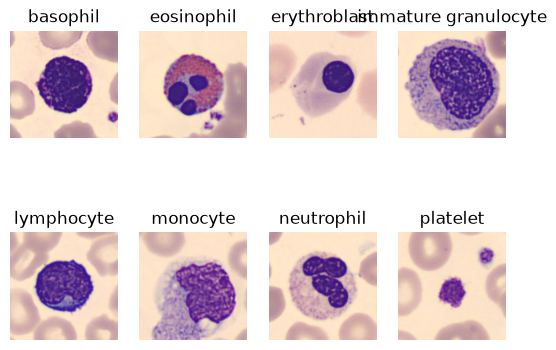

In [5]:
# Sample images for each class from the dataset
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(df_raw['train_images'][labels.flatten() == i][0], cmap='gray')
    plt.title(f"{CLASS_NAMES[i]}")
    plt.axis('off')


Distribution of labels in the training set:


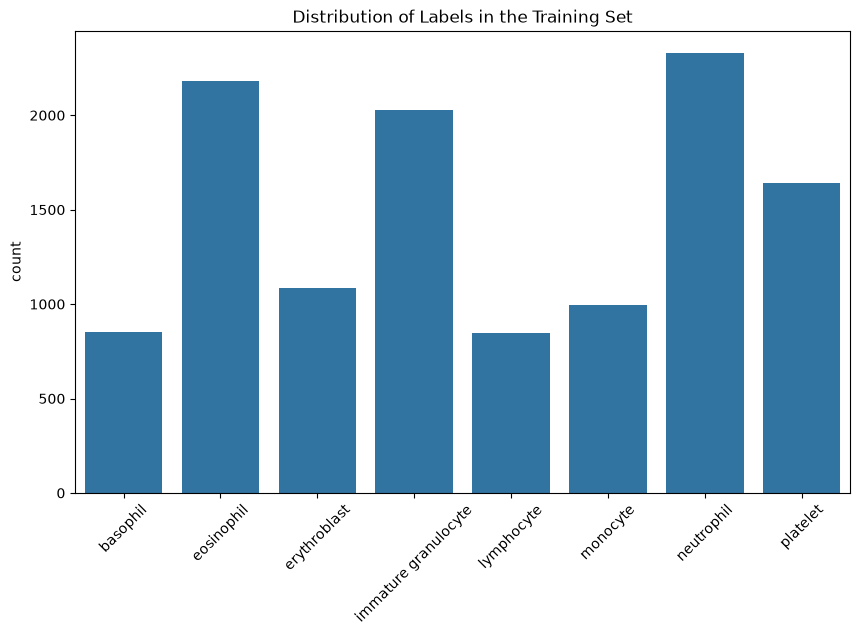

In [6]:
# showing the distribution of labels in the training set
plt.figure(figsize=(10, 6))
sns.countplot(x=labels.flatten())
plt.xticks(ticks=np.arange(8), labels=CLASS_NAMES, rotation=45)
plt.title("Distribution of Labels in the Training Set")
print("\nDistribution of labels in the training set:")

As seen from the class distribution, the dataset is imbalanced, with an imbalance ratio of ~2.74. This imbalance can affect the performance of machine learning models, as they may be biased towards the majority class.

## Augmentation and Class balancing

Class balancing through compute_class_weights

Data augmentation techniques used:
1. flip (horizontal and vertical)
2. rotation (15% or 54 degrees)
3. zoom (10%)

In [7]:
# Class balancing
class_counts = np.arange(8)
weights = compute_class_weight(
    class_weight='balanced', 
    classes=class_counts, 
    y=labels.flatten()
)

class_weights = dict(zip(class_counts, weights))
print("\nClass weights for balancing the dataset:")
for i, weight in class_weights.items():
    print(f"Class {i} ({CLASS_NAMES[i]}): Weight = {weight:.4f}")


Class weights for balancing the dataset:
Class 0 (basophil): Weight = 1.7545
Class 1 (eosinophil): Weight = 0.6854
Class 2 (erythroblast): Weight = 1.3778
Class 3 (immature granulocyte): Weight = 0.7378
Class 4 (lymphocyte): Weight = 1.7607
Class 5 (monocyte): Weight = 1.5054
Class 6 (neutrophil): Weight = 0.6416
Class 7 (platelet): Weight = 0.9098


In [8]:
# Augmentation

train_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.15), # 15% rotation or 54 degrees
    tf.keras.layers.RandomZoom(0.1), # 10% zoom
], name="train_augmentation")